# Performance Evaluation: AI Workload (BERT + ResNet50)

In [1]:
# !pip install pandas numpy

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import os, json, glob, re
from typing import Dict, List, Optional
import scienceplots

In [3]:
# ── Shared style ────────────────────────────────────────────────────────────
plt.style.use(['science', 'grid', 'no-latex', 'high-contrast'])
plt.rcParams['pdf.fonttype'] = 42   # TrueType, not Type 3
plt.rcParams['ps.fonttype'] = 42

# Engine color/hatch palette (MMap=blue, IOUring=orange, SCISSOR=green)
ENGINE_STYLE = {
    'MMap':    {'color': '#1f77b4', 'hatch': '//'},
    'IOUring': {'color': '#ff7f0e', 'hatch': '..'},
    'SCISSOR': {'color': '#2ca02c', 'hatch': 'xx'},
}

# FONT = {'title': 13, 'axis': 12, 'tick': 10, 'annot': 9}
FONT = {'title': 11, 'axis': 11, 'tick': 10, 'annot': 10}
# FIG_SIZE_DEFAULT = (6, 3)
# FIG_SIZE_WIDE    = (7, 2.45)   # ratio 2.857:1  (same as original 10×3.5)
# FIG_SIZE_SMALL   = (3.5, 2.5)

FIG_SIZE_DEFAULT = (3.3, 2.2)        # single column
FIG_SIZE_TWOCOL  = (5.0, 2.5)        # two column (figure*)
FIG_SIZE_HALFCOL = (3.3, 2.5)

# Path to DLIO AI-IO benchmark results
AI_RESULTS_DIR = "../data/results/dlio"

fig_dir = "../figures"
os.makedirs(fig_dir, exist_ok=True)

## Data Loading

Each JSON file records a single benchmark run.
Filename format: `{workload}_{engine}_r{N}.json`

Throughput is already aggregated per run in each file as `throughput_gbs`.
We take the **mean across runs** for each (workload, engine) combination.

In [4]:
def load_ai_results(results_dir: str) -> pd.DataFrame:
    """
    Load all JSON result files from results_dir.

    Returns a DataFrame with columns:
        workload, engine, run, throughput_gbs, total_requests
    where throughput_gbs and total_requests are per-run values from the JSON.
    """
    pattern = os.path.join(results_dir, "*.json")
    json_files = sorted(glob.glob(pattern))

    if not json_files:
        raise FileNotFoundError(f"No JSON files found in {results_dir}")

    records = []
    for fpath in json_files:
        fname = os.path.basename(fpath)
        match = re.match(
            r'^(bert_clustered|resnet50_clustered)_(.+)_r(\d+)\.json$',
            fname
        )
        if match is None:
            print(f"Skipping unrecognised file: {fname}")
            continue

        workload = match.group(1)
        engine = match.group(2)
        run = int(match.group(3))

        with open(fpath) as f:
            data = json.load(f)

        throughput_gbs = data.get('throughput_gbs')
        if throughput_gbs is None:
            print(f"Warning: 'throughput_gbs' missing in {fname}")
            continue

        records.append({
            'workload':        workload,
            'engine':          engine,
            'run':             run,
            'throughput_gbs':  float(throughput_gbs),
            'total_requests':  int(data.get('total_requests', 0)),
        })

    df = pd.DataFrame(records)
    print(f"Loaded {len(df)} records from {len(json_files)} files")
    return df

In [5]:
raw_df = load_ai_results(AI_RESULTS_DIR)
raw_df.head(10)

Loaded 64 records from 64 files


,workload,engine,run,throughput_gbs,total_requests
0,bert_clustered,io_uring,1,0.1244,1049134
1,bert_clustered,io_uring,2,0.1761,1049134
2,bert_clustered,mmap,1,0.0727,1049134
3,bert_clustered,mmap,2,0.0837,1049134
4,bert_clustered,scissor_g0,1,0.0163,1049134
5,bert_clustered,scissor_g0,2,0.0141,1049134
6,bert_clustered,scissor_g16,1,0.1017,1049134
7,bert_clustered,scissor_g16,2,0.1409,1049134
8,bert_clustered,scissor_g1,1,0.0213,1049134
9,bert_clustered,scissor_g1,2,0.0260,1049134


In [6]:
# Aggregate: mean throughput and total_requests across runs per (workload, engine)
agg_df = (
    raw_df.groupby(['workload', 'engine'])
          .agg(mean_throughput_gbs=('throughput_gbs', 'mean'),
               total_requests=('total_requests', 'first'))
          .reset_index()
)

print(agg_df.sort_values(['workload', 'engine']).to_string(index=False))

          workload         engine  mean_throughput_gbs  total_requests
    bert_clustered       io_uring              0.15025         1049134
    bert_clustered           mmap              0.07820         1049134
    bert_clustered        scissor              0.09725         1049134
    bert_clustered     scissor_g0              0.01520         1049134
    bert_clustered     scissor_g1              0.02365         1049134
    bert_clustered    scissor_g16              0.12130         1049134
    bert_clustered     scissor_g2              0.04735         1049134
    bert_clustered     scissor_g4              0.08065         1049134
    bert_clustered     scissor_g8              0.10060         1049134
    bert_clustered     scissor_sr              0.23225         1049134
    bert_clustered  scissor_sr_g0              0.23560         1049134
    bert_clustered  scissor_sr_g1              0.31490         1049134
    bert_clustered scissor_sr_g16              0.27270         1049134
    be

## Engine Grouping

Engines fall into several groups:
- `mmap`: baseline MMap
- `io_uring`: io_uring baseline
- `scissor`: SCISSOR (no coalescing gap, i.e. g0 by default)
- `scissor_gN`: SCISSOR with gap=N
- `scissor_sr`: SCISSOR with selective-read
- `scissor_sr_gN`: SCISSOR selective-read with gap=N

In [7]:
def engine_display_name(engine: str) -> str:
    """Convert raw engine key to a readable display label."""
    mapping = {
        'mmap': 'MMap',
        'io_uring': 'IOUring',
        'scissor': 'SCISSOR',
    }
    if engine in mapping:
        return mapping[engine]
    # scissor_gN
    m = re.match(r'^scissor_g(\d+)$', engine)
    if m:
        return f'SCISSOR g{m.group(1)}'
    # scissor_sr
    if engine == 'scissor_sr':
        return 'SCISSOR-SR'
    # scissor_sr_gN
    m = re.match(r'^scissor_sr_g(\d+)$', engine)
    if m:
        return f'SCISSOR-SR g{m.group(1)}'
    return engine


def engine_style(engine: str) -> dict:
    """Return {'color': ..., 'hatch': ...} for an engine key."""
    if engine == 'mmap':
        return ENGINE_STYLE['MMap']
    if engine == 'io_uring':
        return ENGINE_STYLE['IOUring']
    # All SCISSOR variants use green, varying the hatch
    scissor_hatches = ['xx', '//', '\\\\', '++', '..', 'oo', '--']
    scissor_engines = sorted([
        e for e in agg_df['engine'].unique()
        if e not in ('mmap', 'io_uring')
    ])
    idx = scissor_engines.index(engine) if engine in scissor_engines else 0
    return {
        'color': ENGINE_STYLE['SCISSOR']['color'],
        'hatch': scissor_hatches[idx % len(scissor_hatches)]
    }

## Plot: Throughput per Engine per Workload

In [8]:
def _fmt_iops(n: int) -> str:
    if n >= 1_000_000:
        return f"{n / 1_000_000:.1f}M"
    return f"{n / 1_000:.0f}K"


def plot_ai_throughput_overview(
    agg_df: pd.DataFrame,
    workloads: Optional[List[str]] = None,
    save_dir: Optional[str] = None
):
    """
    Bar plot: MMap, IOUring, and the best scissor_sr_* variant per workload
    (labelled 'SCISSOR'). X-tick labels show engine name and IOP count,
    matching the nb_statediff convention.
    """
    if workloads is None:
        workloads = sorted(agg_df['workload'].unique())

    n = len(workloads)
    fig, axes = plt.subplots(1, n, figsize=FIG_SIZE_TWOCOL, sharey=False)
    if n == 1:
        axes = [axes]

    workload_titles = {
        'bert_clustered':     'BERT',
        'resnet50_clustered': 'ResNet50',
    }

    for ax, workload in zip(axes, workloads):
        wdf = agg_df[agg_df['workload'] == workload]

        # Pick best scissor_sr_* by mean throughput
        sr_rows = wdf[wdf['engine'].str.match(r'^scissor_sr')]
        if sr_rows.empty:
            best_sr_engine = None
        else:
            best_sr_engine = sr_rows.loc[sr_rows['mean_throughput_gbs'].idxmax(), 'engine']

        # Build ordered list: mmap, io_uring, best scissor_sr
        ordered = [
            ('mmap',     'MMap',    ENGINE_STYLE['MMap']),
            ('io_uring', 'IOUring', ENGINE_STYLE['IOUring']),
        ]
        if best_sr_engine is not None:
            ordered.append((best_sr_engine, 'SCISSOR', ENGINE_STYLE['SCISSOR']))

        x = np.arange(len(ordered))
        bar_width = 0.4

        for xi, (eng, label, style) in enumerate(ordered):
            row = wdf[wdf['engine'] == eng]
            if row.empty:
                continue
            val = row['mean_throughput_gbs'].values[0]
            ax.bar(
                xi, val,
                color=style['color'],
                hatch=style['hatch'],
                edgecolor='black',
                label=label,
            )
            ax.text(
                xi, val * 1.02,
                f"{val:.2f}",
                ha='center', va='bottom',
                fontsize=FONT['annot'], rotation=0
            )

        # Speedup annotation above the SCISSOR bar
        if best_sr_engine is not None:
            uring_val = wdf[wdf['engine'] == 'io_uring']['mean_throughput_gbs'].values
            sr_val    = wdf[wdf['engine'] == best_sr_engine]['mean_throughput_gbs'].values
            if len(uring_val) and len(sr_val):
                speedup = sr_val[0] / uring_val[0]
                # ax.text(
                #     len(ordered) - 1,
                #     sr_val[0] * 1.05,
                #     f"{speedup:.2f}×",
                #     ha='center', va='bottom',
                #     fontsize=FONT['annot'], color='darkgreen', fontweight='bold'
                # )

        y_max = max(
            wdf[wdf['engine'].isin([e for e, *_ in ordered])]['mean_throughput_gbs'].max(),
            0
        )
        ax.set_ylim(0, y_max * 1.2)

        # X-tick labels: "EngineName\nIOP Count", matching nb_statediff style
        xtick_labels = []
        for eng, label, _ in ordered:
            row = wdf[wdf['engine'] == eng]
            iops = int(row['total_requests'].values[0]) if not row.empty else 0
            xtick_labels.append(f"{label}\n{_fmt_iops(iops)}")

        ax.set_xticks(x)
        ax.set_xticklabels(xtick_labels, fontsize=FONT['tick'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_title(workload_titles.get(workload, workload), fontsize=FONT['title'])
        ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
        ax.set_xlabel('Engine / IOP Count', fontsize=FONT['axis'])

    fig.tight_layout()

    if save_dir:
        # fname = os.path.join(save_dir, 'ai_throughput_overview.pdf')
        fname = os.path.join(save_dir, 'ai_e2e_throughput.pdf')
        fig.savefig(fname, dpi=600)
        print(f"Saved figure to {fname}")

    plt.show()

Saved figure to ../figures/ai_e2e_throughput.pdf


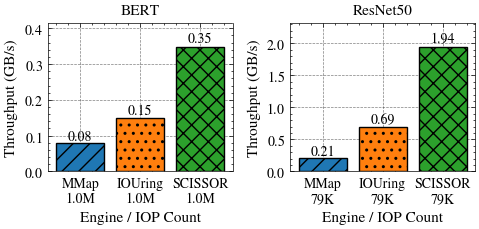

In [9]:
plot_ai_throughput_overview(agg_df, save_dir=fig_dir)

## Plot: SCISSOR Gap Sensitivity

In [10]:
def plot_scissor_gap_sensitivity(
    agg_df: pd.DataFrame,
    workloads: Optional[List[str]] = None,
    figsize=FIG_SIZE_TWOCOL,
    save_dir: Optional[str] = None
):
    """
    Line plot showing scissor_sr_gN throughput as a function of gap size.
    Baselines (mmap, io_uring) shown as horizontal dashed lines.
    """
    if workloads is None:
        workloads = sorted(agg_df['workload'].unique())

    n = len(workloads)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    workload_titles = {
        'bert_clustered':     'BERT (clustered)',
        'resnet50_clustered': 'ResNet50 (clustered)',
    }

    gap_pattern_scissor_sr = re.compile(r'^scissor_sr_g(\d+)$')

    for ax, workload in zip(axes, workloads):
        wdf = agg_df[agg_df['workload'] == workload]

        # Extract scissor_sr_gN gap series only
        scissor_sr_gap_rows = []
        for _, row in wdf.iterrows():
            m = gap_pattern_scissor_sr.match(row['engine'])
            if m:
                scissor_sr_gap_rows.append((int(m.group(1)), row['mean_throughput_gbs']))

        scissor_sr_gap_rows.sort()

        if scissor_sr_gap_rows:
            gaps, thrpts = zip(*scissor_sr_gap_rows)
            ax.plot(
                gaps, thrpts,
                color=ENGINE_STYLE['SCISSOR']['color'],
                marker='s', linewidth=2, label='SCISSOR-SR'
            )
            # Mark the best gap
            best_idx = thrpts.index(max(thrpts))
            ax.scatter(
                [gaps[best_idx]], [thrpts[best_idx]],
                color=ENGINE_STYLE['SCISSOR']['color'],
                s=80, zorder=5
            )
            ax.annotate(
                f"g{gaps[best_idx]}\n{thrpts[best_idx]:.3f} GB/s",
                xy=(gaps[best_idx], thrpts[best_idx]),
                xytext=(8, 6), textcoords='offset points',
                fontsize=FONT['annot'], color='darkgreen'
            )

        # Baseline horizontal lines
        mmap_row = wdf[wdf['engine'] == 'mmap']
        if not mmap_row.empty:
            ax.axhline(
                y=mmap_row['mean_throughput_gbs'].values[0],
                color=ENGINE_STYLE['MMap']['color'],
                linestyle=':', linewidth=2, label='MMap'
            )

        uring_row = wdf[wdf['engine'] == 'io_uring']
        if not uring_row.empty:
            ax.axhline(
                y=uring_row['mean_throughput_gbs'].values[0],
                color=ENGINE_STYLE['IOUring']['color'],
                linestyle=':', linewidth=2, label='IOUring'
            )

        ax.set_title(workload_titles.get(workload, workload), fontsize=FONT['title'])
        ax.set_xlabel('Coalescing Gap (chunks)', fontsize=FONT['axis'])
        ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
        ax.tick_params(axis='both', labelsize=FONT['tick'])
        ax.legend(fontsize=FONT['annot'])
        ax.grid(True, linestyle=':', alpha=0.4)

    fig.tight_layout()

    if save_dir:
        fname = os.path.join(save_dir, 'ai_scissor_gap_sensitivity.pdf')
        fig.savefig(fname, dpi=600)
        print(f"Saved figure to {fname}")

    plt.show()

Saved figure to ../figures/ai_scissor_gap_sensitivity.pdf


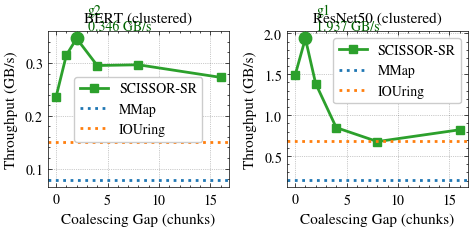

In [11]:
plot_scissor_gap_sensitivity(agg_df, save_dir=fig_dir)

In [12]:
AI_SWEEP_RESULTS_DIR = os.path.join(os.path.dirname(AI_RESULTS_DIR), 'dlio_sweep')

def load_sweep_results(sweep_dir: str) -> pd.DataFrame:
    records = []
    for path in glob.glob(os.path.join(sweep_dir, '*.json')):
        fname = os.path.basename(path)
        m = re.match(r'^(bert_clustered|resnet50_clustered)_(.+)_r(\d+)\.json$', fname)
        if not m:
            continue
        workload, engine, run = m.group(1), m.group(2), int(m.group(3))
        with open(path) as fh:
            data = json.load(fh)
        t = data.get('throughput_gbs')
        if t is not None:
            records.append({'workload': workload, 'engine': engine,
                            'run': run, 'throughput_gbs': float(t)})
    if not records:
        return pd.DataFrame(columns=['workload', 'engine', 'mean_throughput_gbs'])
    df = pd.DataFrame(records)
    return (df.groupby(['workload', 'engine'])
              .agg(mean_throughput_gbs=('throughput_gbs', 'mean'))
              .reset_index())

sweep_df = load_sweep_results(AI_SWEEP_RESULTS_DIR)
print(f"Loaded {len(sweep_df)} engine-workload combinations from sweep results")
sweep_df


Loaded 16 engine-workload combinations from sweep results


,workload,engine,mean_throughput_gbs
0,bert_clustered,scissor_sr_b32mb_g1,0.10300
1,bert_clustered,scissor_sr_b32mb_g2,0.10450
2,bert_clustered,scissor_sr_b32mb_g4,0.10765
3,bert_clustered,scissor_sr_b32mb_g8,0.10275
4,bert_clustered,scissor_sr_g1_b128mb,0.10735
5,bert_clustered,scissor_sr_g1_b256mb,0.11125
6,bert_clustered,scissor_sr_g1_b32mb,0.10835
7,bert_clustered,scissor_sr_g1_b64mb,0.11135
8,resnet50_clustered,scissor_sr_b32mb_g1,0.45590
9,resnet50_clustered,scissor_sr_b32mb_g2,0.47230


In [13]:
import struct as _struct
import collections as _collections

TRACES_DIR = os.path.normpath(os.path.join(
    os.path.dirname(AI_RESULTS_DIR), os.pardir, 'traces'
))

_TRACE_MAGIC      = b'AIOT'
_TRACE_RECORD_FMT = '<IHHQIf'
_TRACE_RECORD_SZ  = _struct.calcsize(_TRACE_RECORD_FMT)

RECORD_SIZE_BYTES = {
    'bert_clustered':     8192,      # 8 KB
    'resnet50_clustered': 163840,    # 160 KB
}

# KEEP_GAPS = {1, 2, 4, 8, 16}
# KEEP_GAPS = {1, 2, 4, 8}
KEEP_GAPS = {0, 1, 2, 4, 8}


def _read_trace(path: str):
    records = []
    with open(path, 'rb') as fh:
        assert fh.read(4) == _TRACE_MAGIC, f'Not an AIOT trace: {path}'
        _ver, n = _struct.unpack('<II', fh.read(8))
        for _ in range(n):
            raw = fh.read(_TRACE_RECORD_SZ)
            step, fid, _, offset, length, _ = _struct.unpack(_TRACE_RECORD_FMT, raw)
            records.append((step, fid, offset, length))
    return records


def compute_gap_stats(trace_path: str, record_size: int,
                       gaps: list[int]) -> tuple[dict, dict]:
    """
    For each gap value compute:
      wasted_pct  -- (bytes_read - bytes_needed) / bytes_read * 100
      iop_count   -- total number of coalesced read segments

    Returns (wasted_pct_dict, iop_count_dict).
    """
    records = _read_trace(trace_path)
    groups: dict = _collections.defaultdict(list)
    for step, fid, offset, _ in records:
        groups[(step, fid)].append(offset // record_size)

    wasted_pct: dict[int, float] = {}
    iop_count:  dict[int, int]   = {}
    for gap in gaps:
        total_read = total_needed = total_iops = 0
        for idxs in groups.values():
            s = sorted(idxs)
            seg_start = seg_end = s[0]
            count = n_segs = 1
            for ci in s[1:]:
                if ci - seg_end <= gap:
                    seg_end = ci
                    count  += 1
                else:
                    total_read   += (seg_end - seg_start + 1) * record_size
                    total_needed += count * record_size
                    n_segs += 1
                    seg_start = seg_end = ci
                    count = 1
            total_read   += (seg_end - seg_start + 1) * record_size
            total_needed += count * record_size
            total_iops   += n_segs
        wasted = total_read - total_needed
        wasted_pct[gap] = (wasted / total_read * 100) if total_read > 0 else 0.0
        iop_count[gap]  = total_iops
    return wasted_pct, iop_count


def _fmt_iop_count(n: int) -> str:
    if n >= 1_000_000:
        return f'{n / 1_000_000:.2g}M'
    return f'{n / 1_000:.0f}K'


# Pre-compute for all displayed gaps
_all_gaps = sorted(KEEP_GAPS)
wasted_pct_by_workload: dict[str, dict] = {}
iop_count_by_workload:  dict[str, dict] = {}
for _wl, _fname in [
    ('bert_clustered',     'bert_clustered_sampled.bin'),
    ('resnet50_clustered', 'resnet50_clustered_sampled.bin'),
]:
    _wp, _ic = compute_gap_stats(
        os.path.join(TRACES_DIR, _fname),
        RECORD_SIZE_BYTES[_wl],
        _all_gaps,
    )
    wasted_pct_by_workload[_wl] = _wp
    iop_count_by_workload[_wl]  = _ic

print('Wasted read % and IOP count by workload:')
for _wl in wasted_pct_by_workload:
    print(f'  {_wl}:')
    for _g in _all_gaps:
        print(f'    g{_g}: {wasted_pct_by_workload[_wl][_g]:.1f}% wasted, '
              f'{_fmt_iop_count(iop_count_by_workload[_wl][_g])} IOPs')

Wasted read % and IOP count by workload:
  bert_clustered:
    g0: 0.0% wasted, 1M IOPs
    g1: 0.0% wasted, 270K IOPs
    g2: 11.2% wasted, 138K IOPs
    g4: 19.4% wasted, 87K IOPs
    g8: 30.6% wasted, 47K IOPs
  resnet50_clustered:
    g0: 0.0% wasted, 79K IOPs
    g1: 0.0% wasted, 32K IOPs
    g2: 19.2% wasted, 13K IOPs
    g4: 35.3% wasted, 3K IOPs
    g8: 39.7% wasted, 1K IOPs


## Plot: Gap Sensitivity Bars (auto batch, used\_chks=1)


In [14]:
def plot_scissor_gap_sensitivity_bars_auto(
    df: pd.DataFrame,
    workloads: Optional[List[str]] = None,
    wasted_pct_by_workload: Optional[dict] = None,
    iop_count_by_workload: Optional[dict] = None,
    figsize=FIG_SIZE_TWOCOL,
    save_dir: Optional[str] = None
):
    """
    Bar chart: SCISSOR-SR throughput vs gap size, auto batch (used_chks=1).
    Matches original gap sweep keys: scissor_sr_gN for N in KEEP_GAPS.
    Secondary y-axis: Unnecessary Read (%) from analytical trace estimate.
    X-tick labels: gap size in KB + IOP count below.
    """
    def _fmt_gap_kb(gap_chunks: int, rec_bytes: int) -> str:
        total_bytes = gap_chunks * rec_bytes
        # if total_bytes >= 1024 * 1024:
        #     return f'{total_bytes / (1024 * 1024):.3g} MB'
        return f'{total_bytes // 1024}'

    if workloads is None:
        workloads = sorted(df['workload'].unique())

    n = len(workloads)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    workload_titles = {
        'bert_clustered':     'BERT',
        'resnet50_clustered': 'ResNet50',
    }

    # Matches: scissor_sr_g1, scissor_sr_g2, scissor_sr_g4, etc.
    gap_pattern = re.compile(r'^scissor_sr_g(\d+)$')
    legend_handles = []
    bar_width = 0.5

    for ax, workload in zip(axes, workloads):
        wdf       = df[df['workload'] == workload]
        rec_bytes = RECORD_SIZE_BYTES.get(workload, 8192)
        rec_kb    = rec_bytes // 1024

        rows = []
        for _, row in wdf.iterrows():
            m = gap_pattern.match(row['engine'])
            if m:
                g = int(m.group(1))
                if g in KEEP_GAPS:
                    rows.append((g, row['mean_throughput_gbs']))
        rows.sort()
        if not rows:
            continue

        gaps, thrpts = zip(*rows)
        x     = list(range(len(gaps)))
        y_max = max(thrpts)

        iop_d = (iop_count_by_workload or {}).get(workload, {})
        xtick_labels = [
            f'{_fmt_gap_kb(g, rec_bytes)}\n{_fmt_iop_count(iop_d[g]) if g in iop_d else ""}'
            for g in gaps
        ]

        bar_h = ax.bar(
            x, thrpts, 
            color=ENGINE_STYLE['SCISSOR']['color'],
            hatch=ENGINE_STYLE['SCISSOR'].get('hatch', 'xx'),
            edgecolor='black', linewidth=0.8,
            label='Throughput'
        )
        if not legend_handles:
            legend_handles += ax.get_legend_handles_labels()[0]

        for xi, val in zip(x, thrpts):
            ax.text(xi, val + y_max * 0.02,
                    f'{val:.2f}', ha='center', va='bottom',
                    fontsize=FONT['annot'])

        ax.set_xticks(x)
        ax.set_xticklabels(xtick_labels, fontsize=FONT['tick'])
        ax.set_xlabel(f'Gap Size (KB) / {rec_kb} KB IOP', fontsize=FONT['axis'])
        if ax is axes[0]:
            ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_title(workload_titles.get(workload, workload), fontsize=FONT['title'])
        ax.set_ylim(0, y_max * 1.35)
        ax.grid(True, axis='y', linestyle=':', alpha=0.4)

        wp_d = (wasted_pct_by_workload or {}).get(workload, {})
        if wp_d:
            wasted_vals = [wp_d.get(g, 0.0) for g in gaps]
            ax2 = ax.twinx()
            line_h, = ax2.plot(
                x, wasted_vals,
                color='red', marker='o', linewidth=2,
                label='Unnecessary Read (%)'
            )
            ax2.set_ylim(0, max(wasted_vals) * 1.4 if max(wasted_vals) > 0 else 10)
            ax2.tick_params(axis='y', labelsize=FONT['tick'])
            if ax is axes[-1]:
                ax2.set_ylabel('Unnecessary Read (%)', fontsize=FONT['axis'])
            # else:
            #     ax2.set_yticklabels([])
            if len(legend_handles) < 2:
                legend_handles.append(line_h)

    legend_labels = ['Throughput', 'Unnecessary Read (%)']
    fig.legend(
        legend_handles, legend_labels[:len(legend_handles)],
        loc='upper center', ncol=len(legend_handles),
        bbox_to_anchor=(0.5, 1.1),
        fontsize=FONT['axis'], frameon=True
    )
    fig.tight_layout()

    if save_dir:
        fname = os.path.join(save_dir, 'ai_scissor_gap_sensitivity_bars_auto.pdf')
        fig.savefig(fname, bbox_inches='tight', pad_inches=0.02, dpi=600)
        print(f'Saved figure to {fname}')

    plt.show()


Saved figure to ../figures/ai_scissor_gap_sensitivity_bars_auto.pdf


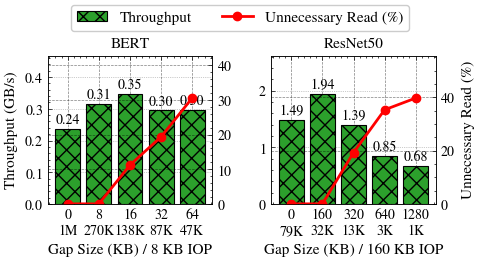

In [15]:
plot_scissor_gap_sensitivity_bars_auto(
    agg_df,
    wasted_pct_by_workload=wasted_pct_by_workload,
    iop_count_by_workload=iop_count_by_workload,
    save_dir=fig_dir,
)


In [16]:
def plot_scissor_gap_sensitivity_bars(
    df: pd.DataFrame,
    workloads: Optional[List[str]] = None,
    wasted_pct_by_workload: Optional[dict] = None,
    iop_count_by_workload: Optional[dict] = None,
    figsize=FIG_SIZE_TWOCOL,
    save_dir: Optional[str] = None
):
    """
    Bar chart: SCISSOR-SR throughput vs gap size, fixed batch=32 MB.
    Matches sweep keys: scissor_sr_b32mb_g{N} for N in KEEP_GAPS.
    Secondary y-axis: Unnecessary Read (%) from analytical trace estimate.
    X-tick labels: gap size in KB + IOP count below.
    """
    def _fmt_gap_kb(gap_chunks: int, rec_bytes: int) -> str:
        total_bytes = gap_chunks * rec_bytes
        # if total_bytes >= 1024 * 1024:
        #     return f'{total_bytes / (1024 * 1024):.3g} MB'
        return f'{total_bytes // 1024}'

    if workloads is None:
        workloads = sorted(df['workload'].unique())

    n = len(workloads)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    workload_titles = {
        'bert_clustered':     'BERT',
        'resnet50_clustered': 'ResNet50',
    }

    # Matches: scissor_sr_b32mb_g1, scissor_sr_b32mb_g4, etc.
    gap_pattern = re.compile(r'^scissor_sr_b\d+mb_g(\d+)$')
    legend_handles = []

    for ax, workload in zip(axes, workloads):
        wdf       = df[df['workload'] == workload]
        rec_bytes = RECORD_SIZE_BYTES.get(workload, 8192)
        rec_kb    = rec_bytes // 1024

        rows = []
        for _, row in wdf.iterrows():
            m = gap_pattern.match(row['engine'])
            if m:
                g = int(m.group(1))
                if g in KEEP_GAPS:
                    rows.append((g, row['mean_throughput_gbs']))
        rows.sort()
        if not rows:
            continue

        gaps, thrpts = zip(*rows)
        x     = list(range(len(gaps)))
        y_max = max(thrpts)

        iop_d = (iop_count_by_workload or {}).get(workload, {})
        xtick_labels = [
            f'{_fmt_gap_kb(g, rec_bytes)}\n{_fmt_iop_count(iop_d[g]) if g in iop_d else ""}'
            for g in gaps
        ]

        bar_h = ax.bar(
            x, thrpts,
            color=ENGINE_STYLE['SCISSOR']['color'],
            hatch=ENGINE_STYLE['SCISSOR'].get('hatch', 'xx'),
            edgecolor='black', linewidth=0.8,
            label='Throughput'
        )
        if not legend_handles:
            legend_handles += ax.get_legend_handles_labels()[0]

        for xi, val in zip(x, thrpts):
            ax.text(xi, val + y_max * 0.02,
                    f'{val:.3f}', ha='center', va='bottom',
                    fontsize=FONT['annot'])

        ax.set_xticks(x)
        ax.set_xticklabels(xtick_labels, fontsize=FONT['tick'])
        ax.set_xlabel(f'Gap Size (KB) / {rec_kb} KB IOP', fontsize=FONT['axis'])
        ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_title(workload_titles.get(workload, workload), fontsize=FONT['title'])
        ax.set_ylim(0, y_max * 1.35)
        ax.grid(True, axis='y', linestyle=':', alpha=0.4)

        # Secondary y-axis: Unnecessary Read (%)
        wp_d = (wasted_pct_by_workload or {}).get(workload, {})
        if wp_d:
            wasted_vals = [wp_d.get(g, 0.0) for g in gaps]
            ax2 = ax.twinx()
            line_h, = ax2.plot(
                x, wasted_vals,
                color='red', marker='o', linewidth=2,
                label='Unnecessary Read (%)'
            )
            ax2.set_ylim(0, max(wasted_vals) * 1.4 if max(wasted_vals) > 0 else 10)
            ax2.tick_params(axis='y', labelsize=FONT['tick'])
            if ax is axes[-1]:
                ax2.set_ylabel('Unnecessary Read (%)', fontsize=FONT['axis'])
            else:
                ax2.set_yticklabels([])
            if len(legend_handles) < 2:
                legend_handles.append(line_h)

    legend_labels = ['Throughput', 'Unnecessary Read (%)']
    fig.legend(
        legend_handles, legend_labels[:len(legend_handles)],
        loc='upper center', ncol=len(legend_handles),
        bbox_to_anchor=(0.5, 1.08),
        fontsize=FONT['tick'], frameon=True
    )
    fig.tight_layout()

    if save_dir:
        fname = os.path.join(save_dir, 'ai_scissor_gap_sensitivity_bars.pdf')
        fig.savefig(fname, bbox_inches='tight', pad_inches=0.02, dpi=600)
        print(f'Saved figure to {fname}')

    plt.show()


Saved figure to ../figures/ai_scissor_gap_sensitivity_bars.pdf


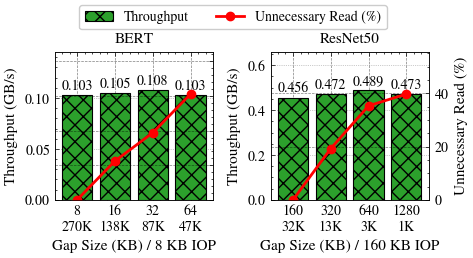

In [17]:
plot_scissor_gap_sensitivity_bars(
    sweep_df,
    wasted_pct_by_workload=wasted_pct_by_workload,
    iop_count_by_workload=iop_count_by_workload,
    save_dir=fig_dir,
)


## Plot: Batch Sweep (fixed gap=1, variable batch size)


In [18]:
def plot_batch_sweep(
    df: pd.DataFrame,
    workloads: Optional[List[str]] = None,
    figsize=FIG_SIZE_TWOCOL,
    save_dir: Optional[str] = None
):
    """
    Bar chart: SCISSOR-SR throughput vs batch size (MB), fixed gap=1 chunk.
    Matches sweep keys: scissor_sr_g1_b{M}mb for M in BATCH_SWEEP_MB_VALUES.
    No secondary y-axis.
    """
    if workloads is None:
        workloads = sorted(df['workload'].unique())

    n = len(workloads)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    workload_titles = {
        'bert_clustered':     'BERT',
        'resnet50_clustered': 'ResNet50',
    }

    # Matches: scissor_sr_g1_b32mb, scissor_sr_g1_b128mb, etc.
    batch_pattern = re.compile(r'^scissor_sr_g\d+_b(\d+)mb$')

    for ax, workload in zip(axes, workloads):
        wdf = df[df['workload'] == workload]

        rows = []
        for _, row in wdf.iterrows():
            m = batch_pattern.match(row['engine'])
            if m:
                rows.append((int(m.group(1)), row['mean_throughput_gbs']))
        rows.sort()
        if not rows:
            continue

        batches, thrpts = zip(*rows)
        x     = list(range(len(batches)))
        y_max = max(thrpts)

        ax.bar(
            x, thrpts,
            color=ENGINE_STYLE['SCISSOR']['color'],
            hatch=ENGINE_STYLE['SCISSOR'].get('hatch', 'xx'),
            edgecolor='black', linewidth=0.8,
        )

        for xi, val in zip(x, thrpts):
            ax.text(xi, val + y_max * 0.02,
                    f'{val:.3f}', ha='center', va='bottom',
                    fontsize=FONT['annot'])

        ax.set_xticks(x)
        ax.set_xticklabels([f'{b}' for b in batches], fontsize=FONT['tick'])
        ax.set_xlabel('Batch Size (MB)', fontsize=FONT['axis'])
        ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
        ax.tick_params(axis='both', labelsize=FONT['tick'])
        ax.set_title(workload_titles.get(workload, workload), fontsize=FONT['title'])
        ax.set_ylim(0, y_max * 1.35)
        ax.grid(True, axis='y', linestyle=':', alpha=0.4)

    fig.tight_layout()

    if save_dir:
        fname = os.path.join(save_dir, 'ai_batch_sweep.pdf')
        fig.savefig(fname, bbox_inches='tight', pad_inches=0.02, dpi=600)
        print(f'Saved figure to {fname}')

    plt.show()


Saved figure to ../figures/ai_batch_sweep.pdf


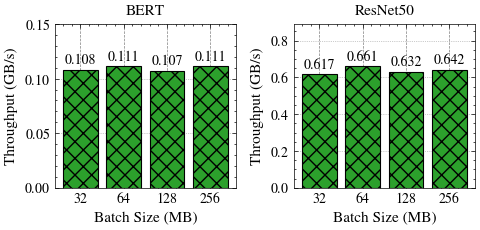

In [19]:
plot_batch_sweep(sweep_df, save_dir=fig_dir)
